# Finite-sample information estimation

Known Gaussian truth permits controlled measurement of estimation bias. A correct parametric assumption can be powerful; sparse discretization and nearest-neighbor methods have different high-dimensional limits.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
from information_lab.estimators import (
    gaussian_pairs,
    gaussian_truth,
    gaussian_plugin,
    ksg,
    binned_plugin,
)

x, y = gaussian_pairs(1024, 4, 0.7, 300041)
print(
    "Known MI",
    gaussian_truth(4, 0.7),
    "Gaussian",
    gaussian_plugin(x, y),
    "KSG",
    ksg(x, y, 5),
    "Binned",
    binned_plugin(x, y, np.linspace(-3, 3, 9)),
)

Known MI 1.9428616956064577 Gaussian 1.9345161403995215 KSG 1.3938198030460935 Binned 7.658117489778411


In [3]:
for method in ["gaussian_plugin", "ksg", "binned_plugin"]:
    record, path = query("estimation", method=method, dimension=16, correlation=0, samples=4096)[0]
    print(method, record["metrics"])

gaussian_plugin {'estimate_bits': 0.04733098083421931, 'true_bits': -0.0, 'seconds': 0.0023823268711566925, 'scope': 'Same independent Gaussian sample pairs per seed across estimators. Empirical discretization has sparse-cell bias; Gaussian plug-in assumes Gaussianity; KSG is continuous and dimension/sample-size sensitive. Finite estimates may be negative or exceed truth and are not clipped.'}


ksg {'estimate_bits': 0.03773834720372497, 'true_bits': -0.0, 'seconds': 3.4593664100393653, 'scope': 'Same independent Gaussian sample pairs per seed across estimators. Empirical discretization has sparse-cell bias; Gaussian plug-in assumes Gaussianity; KSG is continuous and dimension/sample-size sensitive. Finite estimates may be negative or exceed truth and are not clipped.'}


binned_plugin {'estimate_bits': 11.999999999999996, 'true_bits': -0.0, 'seconds': 0.018586217425763607, 'scope': 'Same independent Gaussian sample pairs per seed across estimators. Empirical discretization has sparse-cell bias; Gaussian plug-in assumes Gaussianity; KSG is continuous and dimension/sample-size sensitive. Finite estimates may be negative or exceed truth and are not clipped.'}


The independent 16-dimensional example is a stress test: a positive sparse-histogram estimate can appear despite zero true MI. Estimates are left visible rather than clipped or hidden.

**Recorded configuration**

{
  "family": "estimation",
  "id": "ksg_d4_r70_n4096",
  "method": "ksg",
  "dimension": 4,
  "correlation": 0.7,
  "samples": 4096,
  "neighbors": 5,
  "bin_edges": 9
}
{
  "estimate_bits": 1.6813057087525909,
  "true_bits": 1.9428616956064577,
  "seconds": 0.30080841202288866,
  "scope": "Same independent Gaussian sample pairs per seed across estimators. Empirical discretization has sparse-cell bias; Gaussian plug-in assumes Gaussianity; KSG is continuous and dimension/sample-size sensitive. Finite estimates may be negative or exceed truth and are not clipped."
}


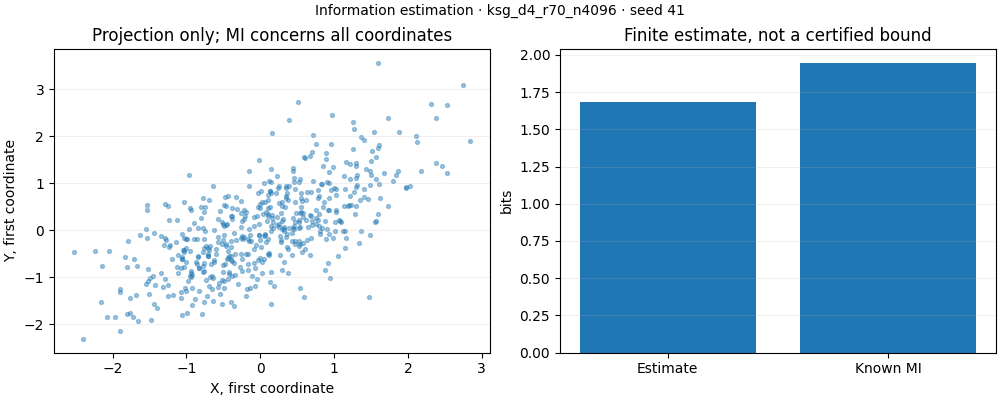

In [4]:
record, path = query("estimation", method="ksg", dimension=4, correlation=0.7, samples=4096)[0]
measured(record)
preview(record)

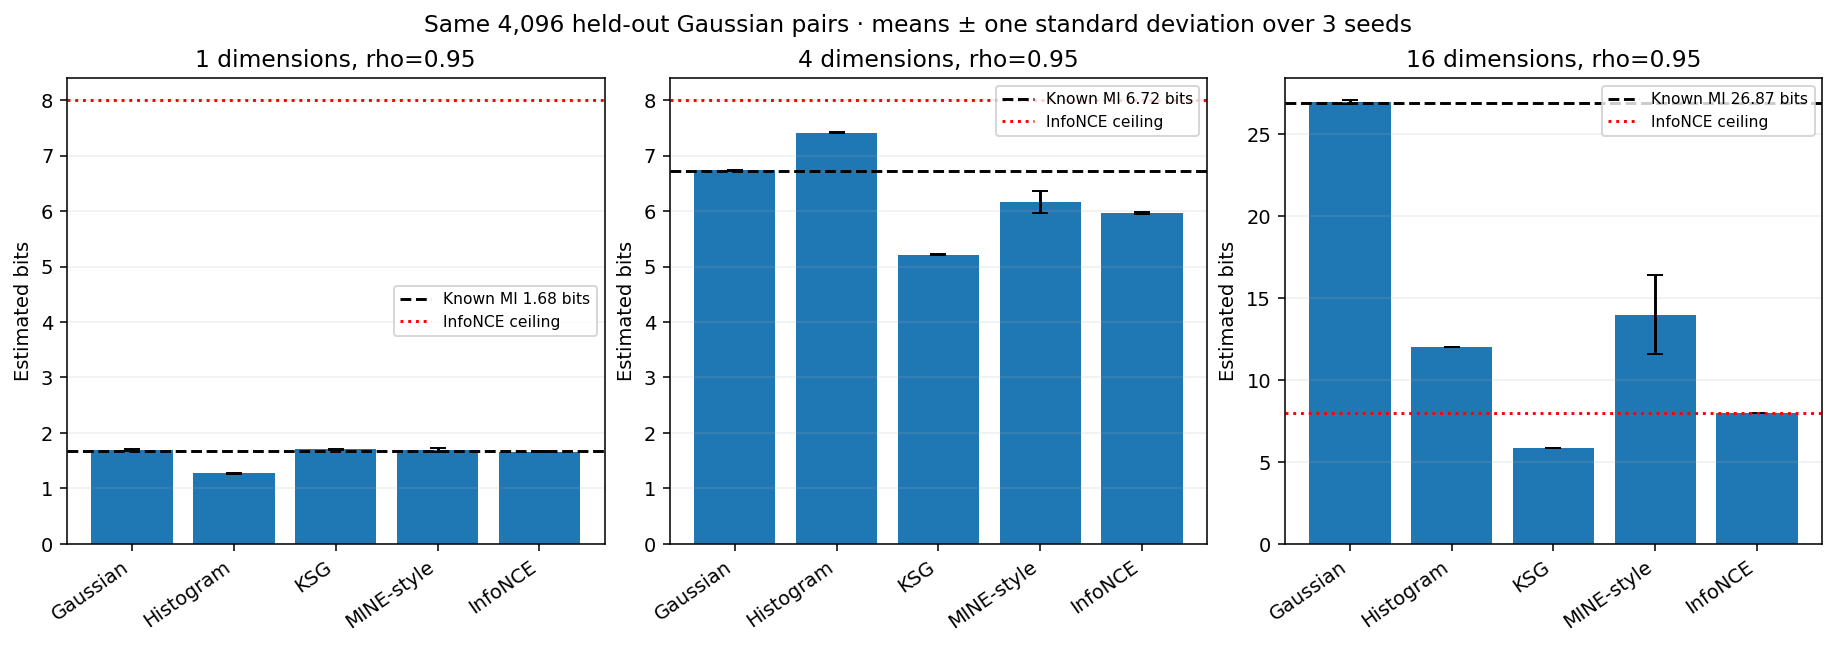

In [5]:
display(Image(filename=str(ROOT / "assets/previews/mi_comparison.png")))

All three classical estimators use the same held-out pair draws for a seed. KSG uses strict Chebyshev neighbor conventions; the reference audit independently recomputes every estimate with brute-force pairwise distances.